In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_wis as wis

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
ALPHA = 0.029
rl_root = "/home/jake/Documents/AI_Clinician/models/rl_models/choc"

cql_dir = os.path.join(rl_root, "cql_with_logprobs", "split_0", "sepsis", "intake-vis",
                       "picu_patients_health_score_from_picu_dataset", "with_actions",
                       "health_score_change_only", "alpha_sweep")
bc_dir = os.path.join(rl_root, "bc_with_logprobs", "split_0", "sepsis", "intake-vis",
                      "picu_patients", "with_actions")

for name, d in (("cql_dir", cql_dir), ("bc_dir", bc_dir)):
    print(f"{name}: {d}")

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
cql_study = R.make_study(cql_dir, family="cql", group_by=(), include=is_alpha, name="cql")
bc_study = R.make_study(bc_dir, family="bc", group_by=(), name="bc")

cql_models = M.load_study_models(cql_study)[()]
bc_models = M.load_study_models(bc_study)[()]
assert sorted(cql_models) == sorted(bc_models) == [0, 1, 2, 3, 4]

# every CQL seed must be paired with the BC seed that shares its state embedding
for s in sorted(cql_models):
    print(s, cql_models[s].record.data_identity.short(), "|", bc_models[s].record.data_identity.short())

store = D.DataStore(keep=("val", "test"))

cql_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep
bc_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/with_actions
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(cql seed 0: actor, critic)
  loaded LoadedModel(cql seed 1: actor, critic)
  loaded LoadedModel(cql seed 2: actor, critic)
  loaded LoadedModel(cql seed 3: actor, critic)
  loaded LoadedModel(cql seed 4: actor, critic)
  loaded LoadedModel(bc seed 0: actor)
  loaded LoadedModel(bc se

In [3]:
results = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                 weight_cap_percentile=None, include_myopic=False)

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: -0.8227  [-0.8227, 5.9534]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         3.7752  [1.1765, 18.2727]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using h

In [4]:
import pandas as pd

def wis_table(results):
    rows = []
    for r in results:
        t, s, ci, dg = r["trajectory_wis"], r["stepwise_wis"], r["bootstrap_ci"], r["weight_diagnostics"]
        rows.append({"seed": r["seed"], "baseline": r["baseline_mean"],
                     "traj": t["value"], "traj_lo": ci["trajectory"]["ci_lower"], "traj_hi": ci["trajectory"]["ci_upper"],
                     "step": s["value"], "step_lo": ci["stepwise"]["ci_lower"], "step_hi": ci["stepwise"]["ci_upper"],
                     "ess_frac": dg["ess_frac"]})
    return pd.DataFrame(rows).round(3)

res_by_cap = {}
for cap in (25, 50):
    print(f"\n######## weight_cap_percentile = {cap}")
    res_by_cap[cap] = wis.run_wis_for_models(cql_models, bc_models, store, split="val", gamma=0.975,
                                             weight_cap_percentile=cap, include_myopic=False)
    display(wis_table(res_by_cap[cap]))
display(wis_table(results))      # the uncapped result, for the same layout


######## weight_cap_percentile = 25

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.1570  [0.2180, 2.0321]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.6457  [0.7488, 2.5255]
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.0387  [0.1958, 1.9740]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.4233  [0.5388, 2.3634]
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2478  [0.3365, 2.1010]  ESS=180.0/240 (75.0%)
  Stepwise WIS:         1.6376  [0.7718, 2.4723]
  Top-1% of trajectories hold 1.7% of total weight (max single trajectory: 0.6%)

=== Seed 3 ===
  [std_source=bc]
  Clinician baseline (logged) retur

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,1.157,0.218,2.032,1.646,0.749,2.525,0.75
1,1,0.883,1.039,0.196,1.974,1.423,0.539,2.363,0.75
2,2,0.883,1.248,0.337,2.101,1.638,0.772,2.472,0.75
3,3,0.883,0.923,0.140,1.966,1.480,0.583,2.441,0.75
4,4,0.883,1.194,0.314,2.092,1.728,0.842,2.607,0.75



######## weight_cap_percentile = 50

=== Seed 0 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.8961  [-0.2778, 1.8981]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         2.1426  [1.0569, 3.2534]
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 1 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 0.6880  [-0.4318, 1.7807]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         1.8153  [0.8534, 2.9296]
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 2 ===
  [std_source=bc]
  Clinician baseline (logged) return: 0.8827 +/- 0.4020 (SEM)
  Trajectory-level WIS: 1.2850  [0.0366, 2.4659]  ESS=120.0/240 (50.0%)
  Stepwise WIS:         2.0468  [0.9581, 3.0593]
  Top-1% of trajectories hold 2.5% of total weight (max single trajectory: 0.8%)

=== Seed 3 ===
  [std_source=bc]
  Clinician baseline (logged) ret

,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,0.896,-0.278,1.898,2.143,1.057,3.253,0.5
1,1,0.883,0.688,-0.432,1.781,1.815,0.853,2.930,0.5
2,2,0.883,1.285,0.037,2.466,2.047,0.958,3.059,0.5
3,3,0.883,0.812,-0.268,1.908,2.287,1.125,3.508,0.5
4,4,0.883,0.934,-0.279,1.928,2.166,1.174,3.220,0.5


,seed,baseline,traj,traj_lo,traj_hi,step,step_lo,step_hi,ess_frac
0,0,0.883,-0.823,-0.823,5.953,3.775,1.176,18.273,0.004
1,1,0.883,0.789,-4.444,1.489,4.063,-2.759,9.576,0.004
2,2,0.883,2.948,-0.740,9.757,4.154,0.760,6.984,0.004
3,3,0.883,-4.440,-4.444,2.999,3.063,1.393,29.918,0.004
4,4,0.883,-4.444,-4.444,11.576,4.330,-2.618,11.594,0.004


CQL seeds loaded: [0]
BC seeds loaded:  [0]
Matched 1 (CQL, BC) pairs by results.json seed: [0]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.981 (traj ESS 98.8%)  step=0.964 (step ESS 98.8%)
  wcap=  5.0  traj=1.135 (traj ESS 95.0%)  step=1.102 (step ESS 95.0%)
  wcap= 10.0  traj=1.002 (traj ESS 90.0%)  step=1.253 (step ESS 90.2%)
  wcap= 25.0  traj=1.157 (traj ESS 75.0%)  step=1.646 (step ESS 75.5%)
  wcap= 50.0  traj=0.896 (traj ESS 50.0%)  step=2.143 (step ESS 51.4%)
  wcap= 75.0  traj=0.592 (traj ESS 25.0%)  step=3.408 (step ESS 26.5%)
  wcap= 90.0  traj=1.838 (traj ESS 10.3%)  step=3.658 (step ESS 11.7%)
  wcap= 95.0  traj=0.488 (traj ESS 5.7%)  step=4.488 (step ESS 6.5%)
  wcap= 99.0  traj=2.549 (traj ESS 1.3%)  step=7.962 (step ESS 1.7%)
CQL seeds loaded: [1]
BC seeds loaded:  [1]
Matched 1 (CQL, BC) pairs by results.json seed: [1]

=== Seed 1: building trajectories once, then sweeping 9 cap levels ===
  wcap=  1.0  traj=0.963 (tra

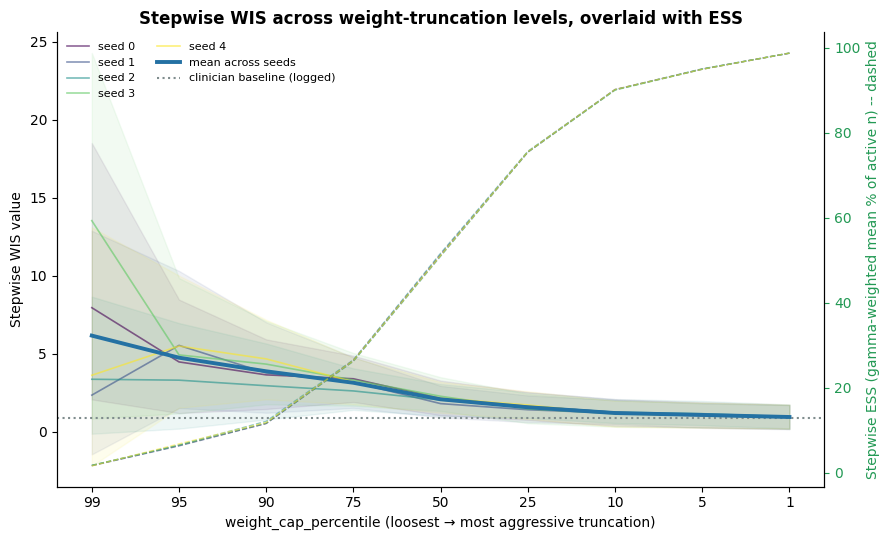

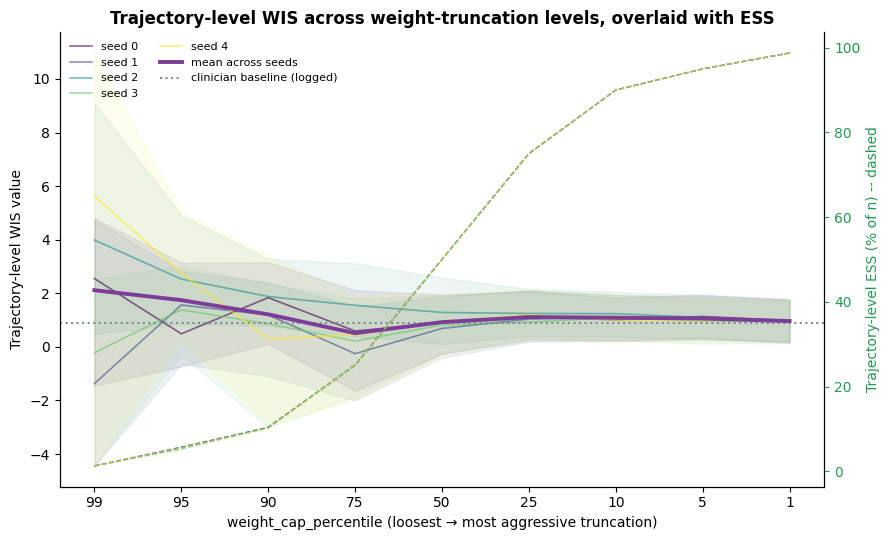

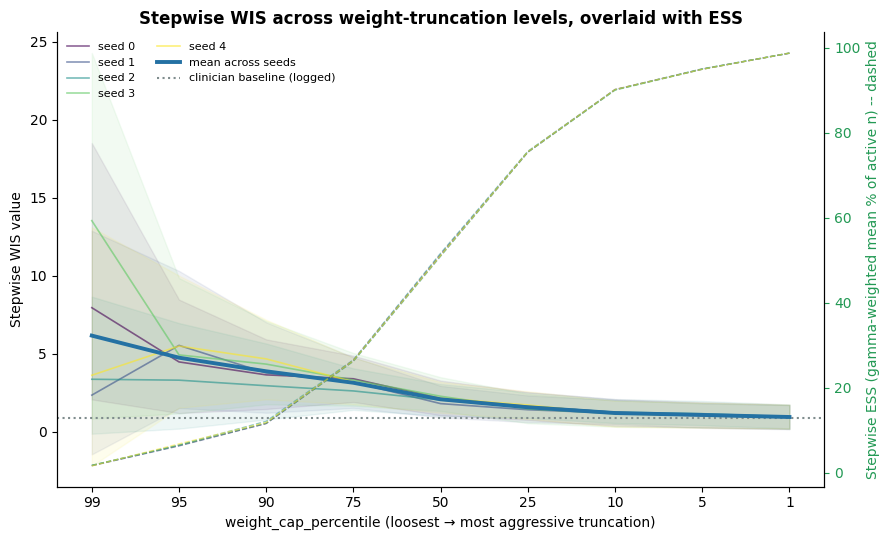

In [5]:
caps = [1, 5, 10, 25, 50, 75, 90, 95, 99]
sweep = wis.run_weight_truncation_sweep_for_models(cql_models, bc_models, store, caps, split="val", n_bootstrap=300)
wis.plot_weight_truncation_sweep(sweep, estimator="trajectory")
wis.plot_weight_truncation_sweep(sweep, estimator="stepwise")

In [6]:
for r in results:
    null_traj = [dict(t, log_ratio=np.zeros_like(t["log_ratio"])) for t in r["trajectories"]]
    print(r["seed"], "stepwise null:", round(wis.compute_stepwise_wis(null_traj, 0.975)["value"], 3),
          "| trajectory null (= baseline):", round(wis.compute_trajectory_wis(null_traj, 0.975)["value"], 3))

0 stepwise null: 0.91 | trajectory null (= baseline): 0.883
1 stepwise null: 0.91 | trajectory null (= baseline): 0.883
2 stepwise null: 0.91 | trajectory null (= baseline): 0.883
3 stepwise null: 0.91 | trajectory null (= baseline): 0.883
4 stepwise null: 0.91 | trajectory null (= baseline): 0.883
